In [11]:
from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache('../cache/dino')

# DINO, built forward

A small ViT learns image features with **no labels**: a student copies a slow-moving teacher across different crops of the same picture. Labels (CIFAR-10's 10 classes) are used only to _score_ the features, never to train them.

### step 0 — the data


In [12]:
import io
from pathlib import Path

import numpy as np
import pyarrow.parquet as pq
import torch
from frozendict import frozendict
from PIL import Image

REPO = Path.cwd().parent
dev = 'cuda'

In [13]:
@cache
def load_cifar():
    # 32x32 colour images, uint8 [N, 32, 32, 3]; labels [N] in 0..9 (only for scoring)
    def split(name: str):
        t = pq.read_table(
            REPO / f'data/cifar10/plain_text/{name}-00000-of-00001.parquet'
        ).to_pydict()
        images = np.stack([np.asarray(Image.open(io.BytesIO(im['bytes']))) for im in t['img']])
        return images, np.array(t['label'])

    return frozendict(train=split('train'), test=split('test'))

load_cifar: cached, 1 call(s) stored


In [14]:
cifar = load_cifar()
for name, (images, labels) in cifar.items():
    print(name, images.shape, images.dtype, labels.shape, np.bincount(labels))

train (50000, 32, 32, 3) uint8 (50000,) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
test (10000, 32, 32, 3) uint8 (10000,) [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


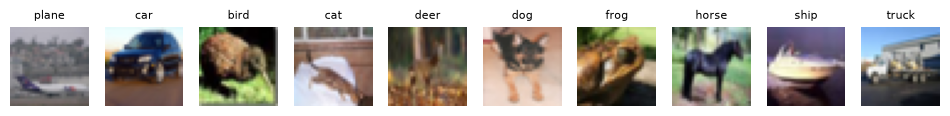

In [15]:
import matplotlib.pyplot as plt

CLASSES = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
images, labels = cifar['train']
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for c, ax in enumerate(axes):
    ax.imshow(images[np.flatnonzero(labels == c)[0]])
    ax.set_title(CLASSES[c], fontsize=8)
    ax.axis('off')

### step 1 — the number to beat: kNN on raw pixels


In [16]:
def knn_accuracy(train_x, train_y, test_x, test_y, k=20):
    # each test vector votes with the classes of its k most similar train vectors (cosine similarity)
    a = torch.nn.functional.normalize(
        torch.as_tensor(train_x, device=dev).flatten(1).float(), dim=1
    )
    b = torch.nn.functional.normalize(torch.as_tensor(test_x, device=dev).flatten(1).float(), dim=1)
    ya, yb = torch.as_tensor(train_y, device=dev), torch.as_tensor(test_y, device=dev)
    nearest = torch.cat([(b[i : i + 1000] @ a.T).topk(k).indices for i in range(0, len(b), 1000)])
    votes = torch.nn.functional.one_hot(ya[nearest], 10).sum(1)
    return (votes.argmax(1) == yb).float().mean().item()

In [17]:
knn_accuracy(*cifar['train'], *cifar['test'])

0.35259997844696045

### step 2 — the whole game

The complete DINO from [dino_parts.py](dino_parts.py): a tiny ViT (2.7M params), 2 big + 4 small crops, a student and its EMA teacher, centring. kNN accuracy on the teacher's features after every epoch; the bar is 35.3% (pixels).


In [18]:
from dino_parts import CFG, train_dino


@cache
def whole_game(cfg=CFG):
    vit, history = train_dino(cifar, cfg)
    return {k: v.cpu() for k, v in vit.state_dict().items()}, history

whole_game: cached, 1 call(s) stored


In [19]:
weights, history = whole_game()

epoch   1  loss 8.038  kNN 30.7%  33s
epoch   2  loss 7.758  kNN 31.0%  65s
epoch   3  loss 7.057  kNN 32.8%  97s
epoch   4  loss 6.760  kNN 34.8%  130s
epoch   5  loss 6.766  kNN 36.3%  162s
epoch   6  loss 6.446  kNN 38.2%  194s
epoch   7  loss 6.568  kNN 39.9%  227s
epoch   8  loss 6.183  kNN 40.9%  259s
epoch   9  loss 5.790  kNN 41.9%  292s
epoch  10  loss 5.836  kNN 43.0%  324s
epoch  11  loss 5.713  kNN 43.8%  357s
epoch  12  loss 5.527  kNN 44.7%  389s
epoch  13  loss 5.749  kNN 45.1%  422s
epoch  14  loss 5.538  kNN 45.4%  454s
epoch  15  loss 5.380  kNN 45.6%  486s
epoch  16  loss 5.484  kNN 45.9%  519s
epoch  17  loss 5.517  kNN 46.1%  551s
epoch  18  loss 5.561  kNN 46.1%  584s
epoch  19  loss 5.603  kNN 46.4%  617s
epoch  20  loss 5.570  kNN 46.3%  648s


### step 3 — box 1: patch embedding

A 4x4 conv with stride 4 cuts the image into non-overlapping 4x4 patches and maps each one to a 192-dim token. 32 px -> 8x8 grid -> 64 tokens.


In [20]:
x = torch.as_tensor(cifar['train'][0][:8]).permute(0, 3, 1, 2) / 255  # [8, 3, 32, 32]
embed = torch.nn.Conv2d(3, 192, kernel_size=4, stride=4)
grid = embed(x)
tokens = grid.flatten(2).transpose(1, 2)
print(x.shape, grid.shape, tokens.shape)

torch.Size([8, 3, 32, 32]) torch.Size([8, 192, 8, 8]) torch.Size([8, 64, 192])


### step 4 — box 2: position embeddings

Attention treats tokens as a set (see practice.ipynb). One learned vector per grid slot, added to whatever token sits there, tells the model where each patch came from.


In [21]:
pos = torch.nn.Parameter(torch.randn(1, 64, 192) * 0.02)  # one vector per slot of the 8x8 grid
placed = tokens + pos  # [8, 64, 192] + [1, 64, 192]: same table for every image
print(pos.shape, placed.shape)

torch.Size([1, 64, 192]) torch.Size([8, 64, 192])


### step 5 — position embeddings for small crops

A 16 px crop is a 4x4 grid (16 tokens), but the table has 64 slots. Treat the table as a 192-channel 8x8 image and resize it to 4x4.


In [22]:
p = pos.reshape(1, 8, 8, 192).permute(0, 3, 1, 2)  # table as an image [1, 192, 8, 8]
p4 = torch.nn.functional.interpolate(p, size=(4, 4), mode='bicubic', align_corners=False)
pos4 = p4.permute(0, 2, 3, 1).flatten(1, 2)  # back to a sequence [1, 16, 192]
print(p.shape, p4.shape, pos4.shape)

torch.Size([1, 192, 8, 8]) torch.Size([1, 192, 4, 4]) torch.Size([1, 16, 192])


# continue in chat - DINO walkthrough notebook
